# Backtesting del sistema adaptativo · USD/CLP

Torneo Banco Itaú y FEN · Vicente Acevedo y José Portillo

Este notebook resume el backtesting de la estrategia:

1. estadísticas de trading por tramo: retorno neto de carry y costos, volatilidad, Sharpe, máxima caída, % de aciertos y número de operaciones;
2. gráficos de la estrategia y sus retornos frente a las referencias del torneo;
3. significancia estadística y lectura de la convicción.

Usa las salidas del walk-forward que están en `resultados/`, así que corre en segundos. Para recalcular todo desde cero, cambie `RECALCULAR = True` en la primera celda de código (≈ 20 minutos en CPU).

El detalle metodológico está en el [informe](informe/README.md).

## Modelos y supuestos

**Qué predice.** Para cada día hábil *t*, la probabilidad *p* de que convenga estar comprado en dólares de *t* a *t+1*, es decir, que el USD/CLP suba más que el carry.

| Pieza | Qué hace | Cómo aprende |
|---|---|---|
| **Modelo 1 · LSTM** | Red recurrente de 16 unidades que lee las 11 variables de los últimos 20 días y entrega una probabilidad (calibración de Platt, promedio de 5 semillas). | Toda la historia con peso exponencial: un día de hace 250 días hábiles pesa la mitad. Se reentrena cada 21 días. |
| **Modelo 1 · Logística** | Regresión logística L2 (C = 0,05) con las 11 variables del día *t*. | Solo los últimos 500 días hábiles. Se reentrena cada 21 días. |
| **Modelo 1 · Combinación** | *p* = promedio simple de ambas probabilidades. | — |
| **Modelo 2 · Confianza** | Compara \|*p* − 0,5\| con los 250 días anteriores. Bajo el percentil 60: 0. Entre 60 y 80: ±1. Sobre 80: ±3. El signo es el de *p* − 0,5. | Umbrales fijos, elegidos en 2015-2021. |
| **Modelo 2 · GARCH(1,1)** | Pronostica la volatilidad de mañana. Si supera 1,5 veces su mediana de 250 días, un ±3 baja a ±1. | 1.000 retornos, reestimado cada 21 días. |

**Variables (11):** retornos del cobre LME y COMEX, oro, DXY y BBDXY, momentum de 20 días del DXY, rand, MSCI EM, cambio de la volatilidad implícita emergente, viernes y días corridos hasta la próxima jornada.

**Supuestos clave:**

- Toda variable del día *t* usa solo cierres conocidos al final de *t*. Como permite el diccionario del laboratorio, los cierres de una misma fecha se consideran disponibles, aunque algunos mercados cierren después de Santiago.
- Walk-forward con embargo de 5 días: cada predicción usa modelos entrenados solo con el pasado.
- Costo de transacción: 1 pb por unidad de cambio de exposición. La exposición 0 rinde 0.
- Carry: (TPM − tasa en dólares) × días corridos / 360, con SOFR desde 2018 y Fed funds antes. El largo lo paga y el corto lo recibe.

## Mecanismo de ejecución

| Elemento | Definición |
|---|---|
| **Momento de la decisión** | Al final del día *t*, cuando están todos los cierres de *t* (los últimos son los de Nueva York, 17:00 ET). |
| **Precio** | Cierre del USD/CLP de la base (`USDCLP Curncy\|PX_LAST`). **No** se usa la apertura ni el dólar observado. |
| **Tenencia** | La exposición *e<sub>t</sub>* ∈ {−3, −1, 0, +1, +3} se mantiene del cierre de *t* al cierre de *t+1*. |
| **Resultado de la jornada** | *e<sub>t</sub>* × [ln(P<sub>t+1</sub>/P<sub>t</sub>) × 10⁴ − carry<sub>t</sub>] − 1 pb × \|*e<sub>t</sub>* − *e<sub>t−1</sub>*\|, en pb. |
| **Qué gatilla una operación** | Cada día se recalcula la exposición con la regla del modelo 2. Se opera cuando cambia el signo de *p* − 0,5 (con exposición distinta de 0), cuando el percentil de confianza cruza 0,6 u 0,8, o cuando el tope del GARCH se activa o se desactiva. No hay *stop loss* ni objetivo de ganancia. |
| **Reentrenamiento** | Cada 21 días hábiles, en el calendario fijo del walk-forward. |

**Para replicar en el monitor:** el script `src/senal_del_dia.py` entrega la exposición *e<sub>t</sub>* con la base hasta *t*, y esa exposición se aplica al retorno de cierre a cierre de *t* a *t+1*.

**Advertencia:** la decisión usa cierres de Nueva York posteriores al cierre de Santiago, pero se valoriza al precio de cierre de Santiago de ese mismo día. Las bases lo permiten. Si el monitor valoriza con un precio posterior (por ejemplo, la apertura de *t+1*), el resultado será menor (informe, secciones 2.4 y 6.5).

In [1]:
import os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RECALCULAR = False      # True: corre preparar_base_v2.py y el walk-forward completo (≈ 20 min en CPU)
BASE = "datos/procesados/modelo_usdclp_desde_2001.csv"
COSTO = 1.0             # pb por unidad de cambio de exposición
TRAMOS = {"Desarrollo p1 · 2005-14": ("2005-01-01", "2014-12-31"),
          "Desarrollo p2 · 2015-21": ("2015-01-01", "2021-12-31"),
          "Validación · 2022-24": ("2022-01-01", "2024-12-31"),
          "Test · 2025-26": ("2025-01-01", "2026-10-05")}

# Abierto en Colab directamente desde GitHub: clona el repositorio y trabaja dentro de él
if not os.path.exists("resultados/posiciones_adaptativo.csv"):
    if not os.path.exists("prediccion-USDCLP"):
        subprocess.run(["git", "clone", "-q", "https://github.com/vichoclo/prediccion-USDCLP.git"], check=True)
    os.chdir("prediccion-USDCLP")
try:
    import holidays, arch  # noqa: F401  (los necesitan preparar_base_v2.py y el walk-forward)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays", "arch", "openpyxl"], check=True)

if RECALCULAR or not os.path.exists(BASE):
    subprocess.run([sys.executable, "src/preparar_base_v2.py", "datos/base_usdclp 2.xlsx", "datos/procesados/"], check=True)
if RECALCULAR:
    subprocess.run([sys.executable, "src/modelo_adaptativo_colab.py", BASE], check=True)
    subprocess.run([sys.executable, "src/evaluacion.py", BASE], check=True)

base = pd.read_csv(BASE, index_col=0, parse_dates=True)
pos = pd.read_csv("resultados/posiciones_adaptativo.csv", header=[0, 1], index_col=0, parse_dates=True)
pd.set_option("display.width", 200, "display.max_columns", 30)
print(f"Base: {base.index[0].date()} → {base.index[-1].date()} · posiciones: {pos.index[0].date()} → {pos.index[-1].date()}")

Base: 2001-08-09 → 2026-10-06 · posiciones: 2006-02-01 → 2026-10-06


## 1. Estrategias comparadas

- **Sistema adaptativo:** la estrategia oficial.
- **Sistema base:** la versión anterior del modelo 1, con toda la historia e igual peso, como control.
- **Referencias del torneo:** comprar siempre (+1), no operar nunca (0) y operar siempre ±1 en la dirección del adaptativo.

In [2]:
idx = pos.index[pos[("Adaptativo", "p")].notna()]       # días en que el sistema emite señal
y_bruto = base["y_ret_pb"].reindex(idx)          # retorno del USD/CLP cierre a cierre, pb
y_neto = base["y_ret_neto_pb"].reindex(idx)      # menos carry
pred = pd.read_csv("resultados/predicciones_modelo1.csv", header=[0, 1], index_col=0, parse_dates=True)
lado = np.sign(pred[("Adaptativo", "p")].reindex(idx) - 0.5)   # dirección del modelo 1 (sin redondear)
EXPO = {"Sistema adaptativo": pos[("Adaptativo", "exposicion")].reindex(idx),
        "Sistema base (control)": pos[("Base (control)", "exposicion")].reindex(idx),
        "Comprar siempre": pd.Series(1.0, idx),
        "Operar siempre ±1": lado,
        "No operar nunca": pd.Series(0.0, idx)}


def diario(e, costo=COSTO, carry=True):
    y = y_neto if carry else y_bruto
    return e * y - costo * e.diff().abs().fillna(e.abs())


def estadisticas(e_total, a, b):
    # Estadísticas de un tramo. Los costos se calculan sobre la serie completa (incluye el cambio de
    # posición del primer día del tramo respecto del día anterior).
    cambios = e_total.diff().abs().fillna(e_total.abs()).loc[a:b]
    e = e_total.loc[a:b]
    ok = y_neto.loc[a:b].notna()                       # días con resultado conocido
    g_neto = (e * y_neto.loc[a:b] - COSTO * cambios)[ok]
    g_sin_costo = (e * y_neto.loc[a:b])[ok]
    g_bruto = (e * y_bruto.loc[a:b])[ok]
    acum = g_neto.cumsum()
    op = (e != 0) & ok
    return {"Retorno bruto %": (np.exp(g_bruto.sum() / 1e4) - 1) * 100,
            "Neto de carry %": (np.exp(g_sin_costo.sum() / 1e4) - 1) * 100,
            "Neto de carry y costos %": (np.exp(g_neto.sum() / 1e4) - 1) * 100,
            "Volatilidad anual %": g_neto.std() * np.sqrt(252) / 100,
            "Sharpe": g_neto.mean() / g_neto.std() * np.sqrt(252) if g_neto.std() > 0 else np.nan,
            "Máxima caída %": (np.exp((acum - acum.cummax()).min() / 1e4) - 1) * 100,
            "% aciertos (días operados)": 100 * (np.sign(e[op]) == np.sign(y_neto.loc[a:b][op])).mean() if op.any() else np.nan,
            "N° operaciones": int((cambios > 0).sum()),
            "Unidades negociadas": float(cambios.sum()),
            "% días operados": 100 * op.sum() / ok.sum(),
            "Días": int(ok.sum())}


filas = []
for tramo, (a, b) in TRAMOS.items():
    for nombre, e in EXPO.items():
        filas.append({"Tramo": tramo, "Estrategia": nombre, **estadisticas(e, a, b)})
T = pd.DataFrame(filas).set_index(["Tramo", "Estrategia"])
T.round(2)

Retorno bruto %  Neto de carry %  Neto de carry y costos %  Volatilidad anual %  Sharpe  Máxima caída %  % aciertos (días operados)  N° operaciones  \
Tramo                   Estrategia                                                                                                                                                                    
Desarrollo p1 · 2005-14 Sistema adaptativo               259.46           271.05                    205.25                12.43    1.12          -15.85                       54.05            1091   
                        Sistema base (control)            99.13           122.56                     85.54                13.29    0.58          -35.93                       53.33            1072   
                        Comprar siempre                   22.35            -2.91                     -2.92                10.89   -0.03          -37.45                       48.99               1   
                        Operar siempre ±1                 85.19            89.96                     62.18                10.88    0.55          -26.24                       51.46             855   
                        No operar nunca                    0.00             0.00                      0.00                 0.00     NaN            0.00                         NaN               0   
Desarrollo p2 · 2015-21 Sistema adaptativo               202.48           188.36                    137.37                16.02    0.79          -19.75                       53.27             952   
                        Sistema base (control)           385.61           373.44                    284.34                16.88    1.17          -16.16                       53.80             970   
                        Comprar siempre                   33.48            20.52                     20.52                11.11    0.25          -23.31                       50.12               0   
                        Operar siempre ±1                 91.00            86.66                     63.93                11.11    0.65          -17.83                       51.22             655   
                        No operar nunca                    0.00             0.00                      0.00                 0.00     NaN            0.00                         NaN               0   
Validación · 2022-24    Sistema adaptativo                69.61            77.21                     63.71                20.93    0.80          -24.58                       53.65             397   
                        Sistema base (control)           124.98           126.26                    107.74                21.41    1.16          -18.61                       55.95             425   
                        Comprar siempre                   18.04             3.03                      3.03                16.43    0.06          -29.68                       50.87               0   
                        Operar siempre ±1                 -7.00            -3.33                     -8.67                16.43   -0.19          -39.58                       51.41             284   
                        No operar nunca                    0.00             0.00                      0.00                 0.00     NaN            0.00                         NaN               0   
Test · 2025-26          Sistema adaptativo                18.26            18.30                     13.37                15.26    0.47          -15.39                       50.32             211   
                        Sistema base (control)           -14.55           -14.40                    -18.53                14.52   -0.81          -29.63                       48.48             245   
                        Comprar siempre                   -3.11            -4.37                     -4.37                12.21   -0.21          -16.93                       47.84               0   
                        Operar siempre ±1                -20.94     

**Cómo leer la tabla:**

- **Retorno bruto:** solo el movimiento del dólar. **Neto de carry:** descuenta el diferencial de tasas. **Neto de carry y costos:** descuenta además 1 pb por unidad de cambio de exposición. Es la cifra central del torneo.
- **N° operaciones:** días en que cambia la exposición. **Unidades negociadas:** suma de los cambios; por ejemplo, de +3 a −1 son 4 unidades.
- **% aciertos:** de los días en que la estrategia tiene posición, en cuántos acertó la dirección neta de carry.

In [3]:
resumen = T["Neto de carry y costos %"].unstack(0)[list(TRAMOS)]
resumen.loc[list(EXPO)].round(1)

Tramo,Desarrollo p1 · 2005-14,Desarrollo p2 · 2015-21,Validación · 2022-24,Test · 2025-26
Estrategia,,,,
Sistema adaptativo,205.2,137.4,63.7,13.4
Sistema base (control),85.5,284.3,107.7,-18.5
Comprar siempre,-2.9,20.5,3.0,-4.4
Operar siempre ±1,62.2,63.9,-8.7,-23.1
No operar nunca,0.0,0.0,0.0,0.0


## 2. Gráficos de la estrategia y sus retornos

### Resultado acumulado y exposición, 2006-2026

Arriba, el resultado acumulado neto de carry y costos (suma de retornos logarítmicos, en puntos porcentuales). Abajo, la exposición vigente del sistema adaptativo cada jornada.

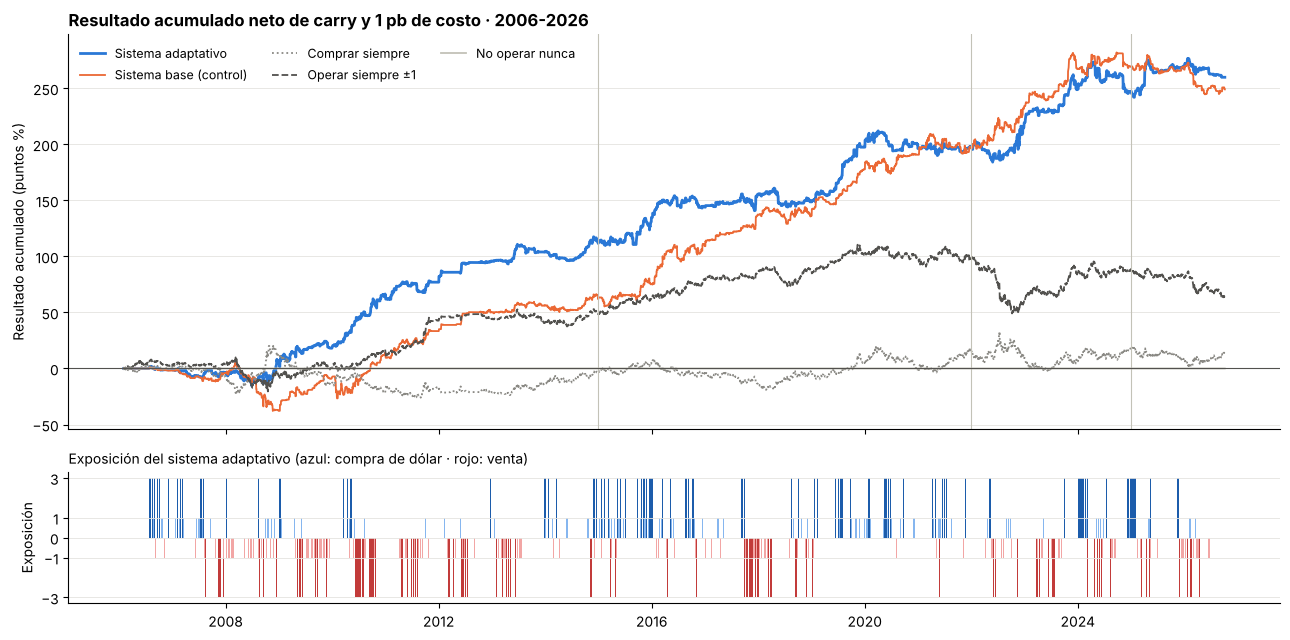

In [4]:
COL = {"Sistema adaptativo": "#2a78d6", "Sistema base (control)": "#eb6834", "Comprar siempre": "#8a8984",
       "Operar siempre ±1": "#52514e", "No operar nunca": "#c3c2b7"}
EST = {"Sistema adaptativo": "-", "Sistema base (control)": "-", "Comprar siempre": ":", "Operar siempre ±1": "--",
       "No operar nunca": "-"}


def panel(a, b, titulo):
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    for nombre, e in EXPO.items():
        g = diario(e).loc[a:b].fillna(0).cumsum() / 100
        ax.plot(g.index, g, color=COL[nombre], ls=EST[nombre], lw=2 if nombre == "Sistema adaptativo" else 1.3, label=nombre)
    for t, (ta, tb) in TRAMOS.items():
        if pd.Timestamp(ta) > pd.Timestamp(a):
            ax.axvline(pd.Timestamp(ta), color="#c3c2b7", lw=0.8)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_ylabel("Resultado acumulado (puntos %)")
    ax.set_title(titulo, loc="left", fontweight="bold")
    ax.legend(frameon=False, ncol=3, fontsize=9)
    e = EXPO["Sistema adaptativo"].loc[a:b]
    col = {-3: "#c23b3a", -1: "#f2a6a5", 0: "#d9d8d4", 1: "#86b6ef", 3: "#1c5cab"}
    ax2.bar(e.index, e, color=[col[int(v)] for v in e], width=1.5)
    ax2.set_yticks([-3, -1, 0, 1, 3]); ax2.set_ylabel("Exposición")
    ax2.set_title("Exposición del sistema adaptativo (azul: compra de dólar · rojo: venta)", loc="left", fontsize=10)
    for x in (ax, ax2):
        x.spines[["top", "right"]].set_visible(False); x.grid(axis="y", color="#e4e3df", lw=0.6)
    fig.tight_layout()
    plt.show()


panel("2006-01-01", "2026-10-05", "Resultado acumulado neto de carry y 1 pb de costo · 2006-2026")

### Test 2025-2026 en detalle

El tramo en que el sistema base dejó de funcionar. El sistema adaptativo se eligió después de ver este tramo (informe, sección 3.5), así que no es una evaluación limpia del adaptativo.

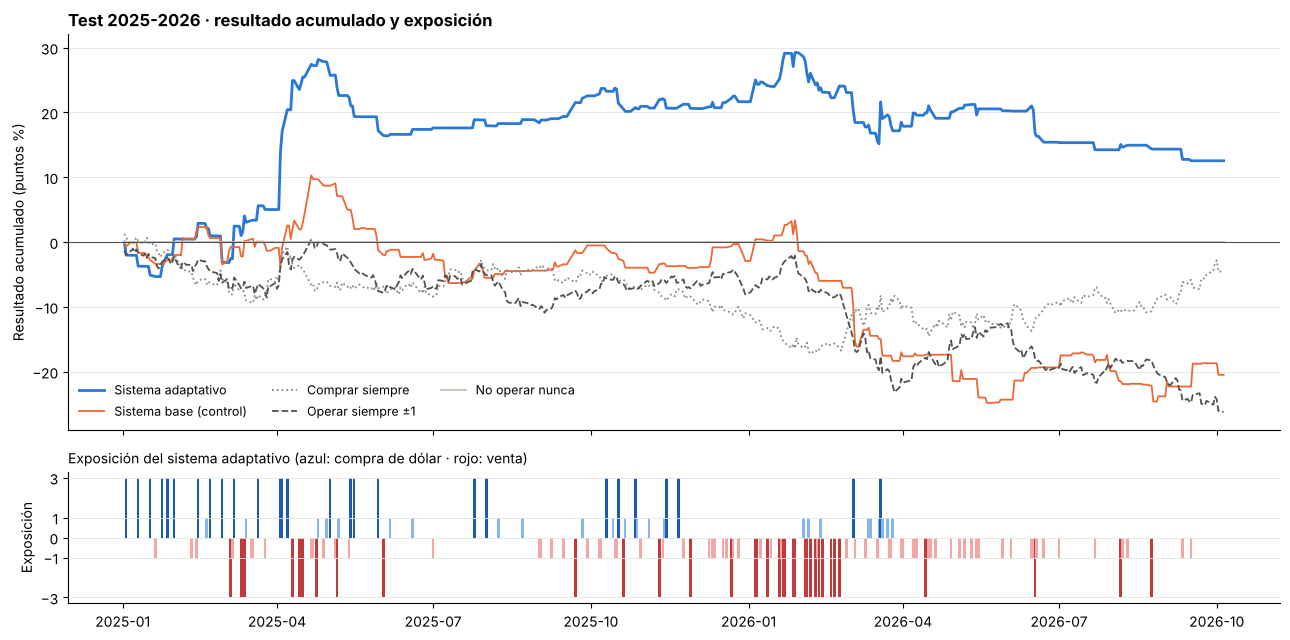

In [5]:
panel("2025-01-01", "2026-10-05", "Test 2025-2026 · resultado acumulado y exposición")

### Caídas desde el máximo

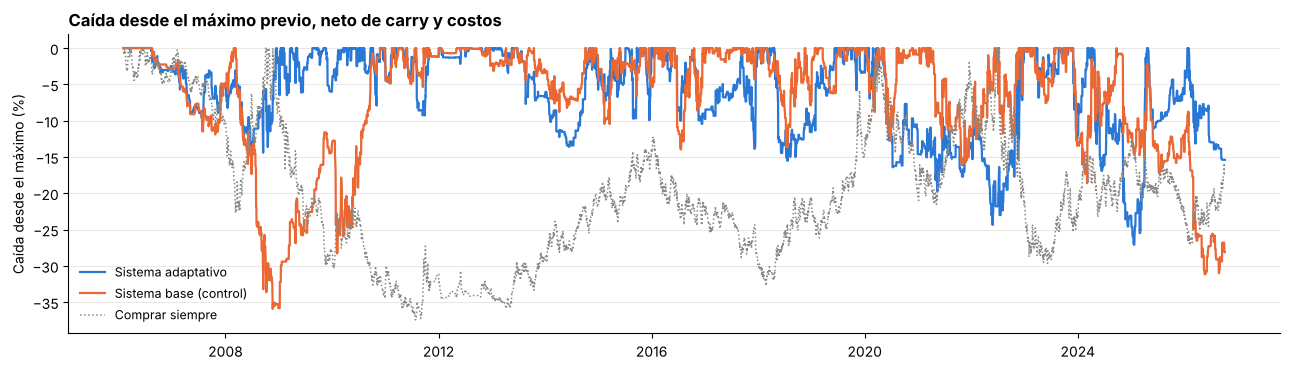

In [6]:
fig, ax = plt.subplots(figsize=(13, 3.8))
for nombre in ("Sistema adaptativo", "Sistema base (control)", "Comprar siempre"):
    g = diario(EXPO[nombre]).fillna(0).cumsum()
    dd = (np.exp((g - g.cummax()) / 1e4) - 1) * 100
    ax.plot(dd.index, dd, color=COL[nombre], ls=EST[nombre], lw=1.6 if nombre != "Comprar siempre" else 1.1, label=nombre)
ax.set_ylabel("Caída desde el máximo (%)"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Caída desde el máximo previo, neto de carry y costos", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e4e3df", lw=0.6)
fig.tight_layout(); plt.show()

### Retorno por año

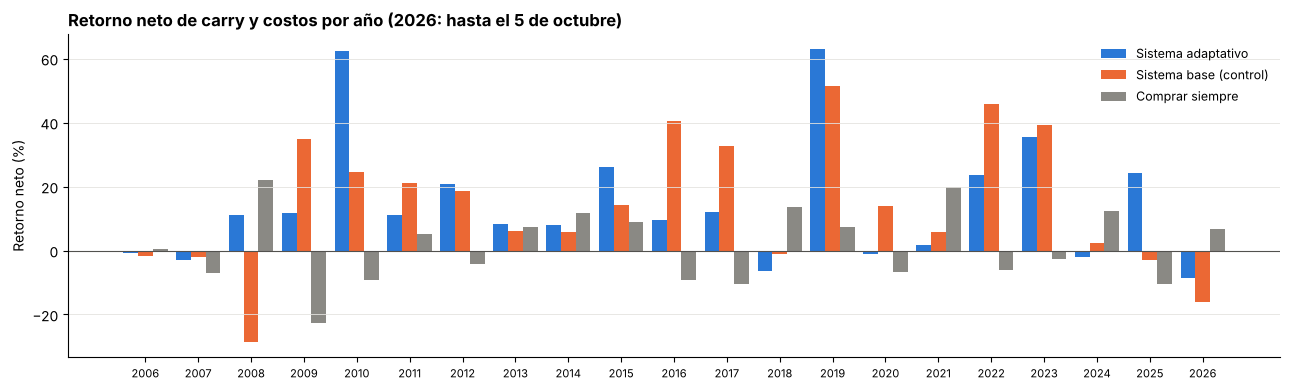

fecha,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Sistema adaptativo,-0.6,-2.9,11.0,11.8,62.3,11.1,20.8,8.2,8.1,26.2,9.5,12.1,-6.5,63.0,-1.2,1.8,23.5,35.4,-2.0,24.2,-8.7
Sistema base (control),-1.9,-2.2,-28.7,34.9,24.6,21.2,18.4,6.0,5.9,14.2,40.5,32.6,-1.1,51.3,13.9,5.9,45.8,39.2,2.4,-2.9,-16.1
Comprar siempre,0.6,-7.0,22.2,-22.6,-9.1,5.1,-4.2,7.3,11.6,9.0,-9.3,-10.4,13.5,7.4,-6.8,19.8,-5.9,-2.5,12.4,-10.4,6.7


In [7]:
anual = pd.DataFrame({n: diario(EXPO[n]).groupby(lambda d: d.year).sum().pipe(lambda s: (np.exp(s / 1e4) - 1) * 100)
                      for n in ("Sistema adaptativo", "Sistema base (control)", "Comprar siempre")})
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(len(anual)); w = 0.28
for i, n in enumerate(anual.columns):
    ax.bar(x + (i - 1) * w, anual[n], width=w, color=COL[n], label=n)
ax.set_xticks(x); ax.set_xticklabels(anual.index, rotation=0, fontsize=8)
ax.axhline(0, color="#52514e", lw=0.8); ax.set_ylabel("Retorno neto (%)"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Retorno neto de carry y costos por año (2026: hasta el 5 de octubre)", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e4e3df", lw=0.6)
fig.tight_layout(); plt.show()
anual.round(1).T

### Sensibilidad a los costos (sistema adaptativo)

In [8]:
sens = {f"{c} pb": {t: (np.exp(diario(EXPO["Sistema adaptativo"], costo=c).loc[a:b].sum() / 1e4) - 1) * 100
                    for t, (a, b) in TRAMOS.items()} for c in (0, 1, 2, 5)}
pd.DataFrame(sens).round(1)

,0 pb,1 pb,2 pb,5 pb
Desarrollo p1 · 2005-14,271.0,205.2,151.1,39.8
Desarrollo p2 · 2015-21,188.4,137.4,95.4,9.0
Validación · 2022-24,77.2,63.7,51.2,19.3
Test · 2025-26,18.3,13.4,8.6,-4.4


## 3. Significancia estadística

p unilateral de que la estrategia **no** sea mejor que la referencia, con 1 pb de costo:

- **boot:** bootstrap por bloques de 20 días sobre la diferencia diaria;
- **dm:** Diebold-Mariano con Newey-West.

También se reportan el placebo (% de direcciones al azar, con la misma exposición, que ganan más) y el Sharpe deflactado por ~349 configuraciones probadas. Lo calcula `src/evaluacion.py`; aquí se lee su salida.

In [9]:
sig = pd.read_csv("resultados/eval_significancia.csv")
cols = ["senal", "tramo", "boot_vs_±1", "boot_vs_comprar", "boot_vs_no operar", "dm_vs_±1", "dm_vs_comprar",
        "dm_vs_no operar", "placebo_%", "dsr_P", "mejora_LL_x1000", "t_LL"]
sig[sig.senal.isin(["adaptativo", "base"])][cols].set_index(["senal", "tramo"])

boot_vs_±1  boot_vs_comprar  boot_vs_no operar  dm_vs_±1  dm_vs_comprar  dm_vs_no operar  placebo_%  dsr_P  mejora_LL_x1000  t_LL
senal      tramo                                                                                                                                        
adaptativo p1_05_14         0.026            0.015              0.001     0.021          0.018            0.001        0.0  0.595             0.94  0.39
           p2_15_21         0.151            0.076              0.024     0.142          0.076            0.021        0.5  0.188            -0.07 -0.03
           val_22_24        0.028            0.188              0.089     0.031          0.189            0.103        5.3  0.060             1.61  0.53
           test_25_26       0.013            0.237              0.281     0.024          0.269            0.294       19.8  0.008            -6.32 -1.67
base       p1_05_14         0.043            0.137              0.053     0.045          0.156            0.058        1.8  0.094             1.68  1.14
           p2_15_21         0.029            0.013              0.002     0.029          0.013            0.001        0.0  0.545             1.88  1.01
           val_22_24        0.013            0.096              0.030     0.023          0.092            0.029        1.4  0.169             3.80  1.67
           test_25_26       0.682            0.678              0.826     0.693          0.725            0.855       77.9  0.000            -4.51 -1.45

## 4. Lectura de la convicción

Cómo se reparte la exposición y cuánto aporta cada nivel (sistema adaptativo, 1 pb).

In [10]:
cv = pd.read_csv("resultados/eval_conviccion.csv")
cv[cv.senal == "adaptativo"].drop(columns="senal").set_index(["tramo", "nivel"])

dias  %dias  acierto_%  ret_direccion_pb  resultado_medio_pb  aporte_%  aporte_pb
tramo      nivel                                                                                   
p1_05_14   0      1257     62       49.9              -0.1                -0.6        -7       -765
           1       460     23       53.5               7.2                 6.2        26       2861
           3       306     15       54.9              10.7                29.6        81       9064
p2_15_21   0      1016     59       49.8               1.3                -0.7        -8       -719
           1       359     21       51.0               5.7                 4.5        19       1627
           3       345     20       55.7               8.2                22.4        89       7736
val_22_24  0       430     58       49.8              -6.6                -0.7        -6       -282
           1       173     23       52.0               5.0                 3.8        13        661
           3       142     19       55.6              11.4                32.0        92       4550
test_25_26 0       284     65       44.0              -8.8                -0.5       -12       -146
           1        91     21       49.5              -6.2                -7.5       -54       -683
           3        64     15       51.6              11.7                32.6       166       2084

**Lectura:**

- Los días con exposición 3 explican casi todo el resultado.
- En los días de abstención (nivel 0), la dirección del modelo acierta como una moneda, así que no operar evita pérdidas.

El diagnóstico completo está en la [sección 7 del informe](informe/07_lectura_conviccion.md).

## 5. Última señal del backtest

La señal para la jornada siguiente al último día de la base. En operación diaria se obtiene con `python src/senal_del_dia.py datos/procesados/modelo_usdclp_desde_2001.csv`, que usa los mismos modelos y parámetros.

In [11]:
ult = pos["Adaptativo"].dropna(subset=["p"]).iloc[-1]
fecha = pos["Adaptativo"].dropna(subset=["p"]).index[-1].date()
print(f"Cierre del {fecha}: p = {ult.p:.3f} · percentil de confianza = {ult.pct_conf:.2f} · "
      f"vol. relativa = {ult.vol_rel:.2f} · exposición = {int(ult.exposicion):+d}")

Cierre del 2026-10-06: p = 0.506 · percentil de confianza = 0.08 · vol. relativa = 1.09 · exposición = +0
